In [1]:
!pip install -q "qiskit>=1.2,<2.0" numba

## 1. Settings


In [2]:
QUICK = False

N_LIST        = [10, 12, 14, 16, 18, 20, 22, 24]
SEEDS_PER_N   = 3
K_FRAC        = 0.4
WEIGHTS       = (1.0, 1.0, 1.0)
LAM_PEN       = 40.0
DEPTHS        = (1, 2)
X_MIXER_MAX_N  = 20
XY_MIXER_MAX_N = 24

MAXITER        = 200
def n_restarts(N):
    return 6 if N <= 12 else 3 if N <= 16 else 2

SHOTS_PER_EVAL = 1000
FINAL_SHOTS    = 1000
CLASSICAL_REPEATS = 30
SA_RUN_LENGTHS = [30, 100, 300, 1000, 3000, 10000, 30000]
TARGET = 0.99

if QUICK:
    N_LIST, SEEDS_PER_N, X_MIXER_MAX_N, MAXITER = [10, 12, 14], 2, 14, 120
    n_restarts = lambda N: 2
    CLASSICAL_REPEATS = 20

## 2. Problem instance and energies


In [3]:
import time, math, warnings
import numpy as np
import pandas as pd
from scipy.optimize import minimize
warnings.filterwarnings("ignore", category=RuntimeWarning)

def make_instance(N, seed, K):
    rng  = np.random.default_rng(seed)
    pop  = rng.integers(20, 100, N).astype(float)
    cost = rng.integers(10, 40, N).astype(float)
    zone = rng.integers(0, 3, N)
    xy   = rng.random((N, 2))
    dist = np.linalg.norm(xy[:, None] - xy[None], axis=-1)
    overlap = np.exp(-dist / 0.25) * np.minimum.outer(pop, pop) * 0.5
    corr = (zone[:, None] == zone[None]).astype(float) * 30.0
    return dict(N=N, K=K, seed=seed, pop=pop, cost=cost, zone=zone, dist=dist, overlap=overlap, corr=corr)

def build_qubo(inst, w_cov, w_cost, w_risk, lam):

    N, K = inst["N"], inst["K"]
    Q = np.triu(w_cov * inst["overlap"] + w_risk * inst["corr"] + 2 * lam, 1)
    Q[np.diag_indices(N)] = -w_cov * inst["pop"] + w_cost * inst["cost"] + lam * (1 - 2 * K)
    return Q, lam * K**2

def energies(states, Q, const, N, chunk=1 << 19):

    out = np.empty(len(states))
    d, U = np.diag(Q).copy(), np.triu(Q, 1)
    sh = np.arange(N, dtype=np.uint64)
    for s in range(0, len(states), chunk):
        B = ((states[s:s + chunk, None].astype(np.uint64) >> sh) & 1).astype(np.float64)
        out[s:s + chunk] = const + B @ d + np.einsum("bi,bi->b", B @ U, B)
    return out

def popcount(a):
    if hasattr(np, "bitwise_count"):
        return np.bitwise_count(a).astype(np.int64)
    c = np.zeros(a.shape, np.int64)
    for i in range(64):
        c += ((a >> i) & 1).astype(np.int64)
    return c

def feasible_states(N, K):
    allx = np.arange(2**N, dtype=np.int64)
    return allx[popcount(allx) == K]

def ising_scale(Q):

    d, U = np.diag(Q), np.triu(Q, 1)
    z  = -(d / 2 + (U.sum(1) + U.sum(0)) / 4)
    return max(np.abs(z).max(), np.abs(U / 4).max())

def true_coverage(inst, x):
    s = np.flatnonzero(x); pop, dist = inst["pop"], inst["dist"]
    if len(s) == 0: return 0.0
    return sum(pop[i] * (1 - np.prod([1 - 0.5 * np.exp(-dist[i, j] / 0.25) for j in s if j != i])) for i in s)

def bits_of(state, N): return np.array([(int(state) >> j) & 1 for j in range(N)], float)

In [4]:
class XSim:

    def __init__(self, diag, N):
        self.diag, self.N = diag, N
    def state(self, th, p):
        N, diag = self.N, self.diag
        psi = np.full(2**N, 1 / np.sqrt(2**N), dtype=complex)
        for l in range(p):
            psi *= np.exp(-1j * th[l] * diag)
            c, s = np.cos(th[p + l]), -1j * np.sin(th[p + l])
            for q in range(N):
                v = psi.reshape(-1, 2, 2**q)
                a = v[:, 0, :].copy(); b = v[:, 1, :]
                v[:, 0, :] = c * a + s * b
                v[:, 1, :] = c * b + s * a
        return psi
    def probs(self, th, p):
        return np.abs(self.state(th, p))**2

class XYSim:
    def __init__(self, states, diag, N):
        self.diag, self.N, self.M = diag, N, len(states)
        pos = np.full(2**N, -1, dtype=np.int64); pos[states] = np.arange(len(states))
        self.pairs = []
        for a in range(N):
            b = (a + 1) % N
            diff = ((states >> a) & 1) != ((states >> b) & 1)
            idx = np.flatnonzero(diff)
            partner = pos[states[idx] ^ ((1 << a) | (1 << b))]
            self.pairs.append((idx, partner))
        del pos
    def state(self, th, p):
        psi = np.full(self.M, 1 / np.sqrt(self.M), dtype=complex)
        for l in range(p):
            psi *= np.exp(-1j * th[l] * self.diag)
            c2, s2 = np.cos(2 * th[p + l]), -1j * np.sin(2 * th[p + l])
            for idx, partner in self.pairs:
                old, oth = psi[idx], psi[partner]
                psi[idx] = c2 * old + s2 * oth
        return psi
    def probs(self, th, p):
        return np.abs(self.state(th, p))**2

def train_qaoa(sim, diag, p, restarts, maxiter, seed, warm=None, prev=None):

    nfev = 0
    def f(th):
        nonlocal nfev; nfev += 1
        return float(sim.probs(th, p) @ diag)
    rng = np.random.default_rng(seed)
    starts = [rng.uniform(0, np.pi / 2, 2 * p) for _ in range(restarts)]
    if warm is not None and len(warm) == 2 * p:
        starts[0] = np.array(warm)
    if prev is not None and len(prev) == 2 * (p - 1):
        q = p - 1
        starts[-1] = np.r_[prev[:q], 0.0, prev[q:], 0.0]
    t0, best = time.time(), None
    for x0 in starts:
        r = minimize(f, x0, method="COBYLA", options={"maxiter": maxiter})
        if best is None or r.fun < best.fun: best = r
    return sim.probs(best.x, p), best.x, nfev, time.time() - t0

In [5]:
from qiskit import QuantumCircuit
from qiskit.circuit import ParameterVector
from qiskit.circuit.library import PauliEvolutionGate, StatePreparation
from qiskit.quantum_info import SparsePauliOp, Statevector

def to_ising(Q, const, N):
    def pstr(ops):
        s = ["I"] * N
        for q, P in ops: s[N - 1 - q] = P
        return "".join(s)
    c = const; z = np.zeros(N); terms = []
    for i in range(N):
        c += Q[i, i] / 2; z[i] -= Q[i, i] / 2
        for j in range(i + 1, N):
            q = Q[i, j]
            if q == 0: continue
            c += q / 4; z[i] -= q / 4; z[j] -= q / 4
            terms.append((pstr([(i, "Z"), (j, "Z")]), q / 4))
    terms = [("I" * N, c)] + [(pstr([(i, "Z")]), z[i]) for i in range(N)] + terms
    return SparsePauliOp.from_list(terms).simplify()

def qiskit_ansatz(Hn, N, K, p, mixer):
    g, b = ParameterVector("g", p), ParameterVector("b", p)
    qc = QuantumCircuit(N)
    if mixer == "x":
        qc.h(range(N))
    else:
        allx = np.arange(2**N); vec = (popcount(allx) == K).astype(float); vec /= np.linalg.norm(vec)
        qc.append(StatePreparation(vec), range(N))
    xyop = SparsePauliOp.from_list([("XX", 1.0), ("YY", 1.0)])
    for l in range(p):
        qc.append(PauliEvolutionGate(Hn, time=g[l]), range(N))
        if mixer == "x":
            qc.rx(2 * b[l], range(N))
        else:
            for a in range(N):
                qc.append(PauliEvolutionGate(xyop, time=b[l]), [a, (a + 1) % N])
    return qc, g, b

def verify(N=8, p=2, seed=3):
    K = round(K_FRAC * N); inst = make_instance(N, seed, K)
    rng = np.random.default_rng(0); th = rng.uniform(0, 1.5, 2 * p)
    allx = np.arange(2**N, dtype=np.int64); feas = feasible_states(N, K)
    for mixer, lam in (("x", LAM_PEN), ("xy", 0.0)):
        Q, c = build_qubo(inst, *WEIGHTS, lam=lam)
        scale = ising_scale(Q)
        Hn = (to_ising(Q, c, N) / scale).simplify()
        qc, g, b = qiskit_ansatz(Hn, N, K, p, mixer)
        qc = qc.assign_parameters({g: th[:p], b: th[p:]})
        pq = Statevector(qc).probabilities()
        if mixer == "x":
            mine = XSim(energies(allx, Q, c, N) / scale, N).probs(th, p)
        else:
            sub = XYSim(feas, energies(feas, Q, c, N) / scale, N).probs(th, p)
            mine = np.zeros(2**N); mine[feas] = sub
        print(f"  {mixer:>2}-mixer: max |Qiskit - fast simulator| = {np.abs(pq - mine).max():.2e}")
        assert np.abs(pq - mine).max() < 1e-8

print("Checking fast simulators against Qiskit (N=8, p=2):")
verify()

inst = make_instance(10, 7, 4); Q, c = build_qubo(inst, *WEIGHTS, lam=0.0)
fs = feasible_states(10, 4); v = energies(fs, Q, c, 10); o = fs[v.argmin()]
print("v1 instance optimum:", np.flatnonzero(bits_of(o, 10)).tolist(), round(v.min(), 1), "(v1 said [0, 2, 3, 6], -216.5)")

Checking fast simulators against Qiskit (N=8, p=2):
   x-mixer: max |Qiskit - fast simulator| = 2.78e-17
  xy-mixer: max |Qiskit - fast simulator| = 1.32e-15
v1 instance optimum: [0, 2, 3, 6] -216.5 (v1 said [0, 2, 3, 6], -216.5)


## 5. Classical baselines (compiled with Numba so they are fast)

All of them only look at "exactly K sites" solutions and count every candidate they score as **one evaluation**.

* **Greedy** — add the best site K times (v1 baseline).
* **SA** — simulated annealing with swap moves (close one site, open another), temperature cooling from hot to cold.
* **LS (2-swap local search)** — start from the greedy answer (greedy's evaluations are charged to LS), try every swap, take the best one, repeat until nothing improves; then restart from a random solution until the budget runs out.
* **Random** — draw random feasible solutions (computed exactly, no simulation needed).

In [6]:
from numba import njit

def qubo_parts(Q):
    U = np.triu(Q, 1)
    return np.ascontiguousarray(np.diag(Q)), np.ascontiguousarray(U + U.T)

@njit
def _energy(x, d, W):
    n = len(x); e = 0.0
    for i in range(n):
        if x[i]:
            e += d[i]
            for j in range(i + 1, n):
                if x[j]: e += W[i, j]
    return e

@njit
def _field(x, W):
    n = len(x); g = np.zeros(n)
    for i in range(n):
        if x[i]:
            for k in range(n): g[k] += W[k, i]
    return g

@njit
def sa_run(d, W, K, budget, T0, T1, seed, target):

    np.random.seed(seed)
    N = len(d); perm = np.random.permutation(N)
    x = np.zeros(N, np.int64); sel = perm[:K].copy(); uns = perm[K:].copy()
    for i in sel: x[i] = 1
    g = _field(x, W); E = _energy(x, d, W); best = E; hit = 1 if E <= target else -1
    for t in range(1, budget):
        T = T0 * (T1 / T0) ** (t / max(budget - 1, 1))
        a = np.random.randint(K); b = np.random.randint(N - K)
        i = sel[a]; j = uns[b]
        delta = -(d[i] + g[i]) + (d[j] + g[j] - W[i, j])
        if delta <= 0 or np.random.random() < np.exp(-delta / T):
            x[i] = 0; x[j] = 1; sel[a] = j; uns[b] = i; E += delta
            for k in range(N): g[k] += W[k, j] - W[k, i]
            if E < best:
                best = E
                if hit < 0 and best <= target: hit = t + 1
    return best, hit

@njit
def ls_run(d, W, K, budget, x0, seed, target):

    np.random.seed(seed)
    N = len(d); evals = 0; best = 1e300; hit = -1; first = True
    while evals < budget:
        if first:
            x = x0.copy(); first = False
        else:
            perm = np.random.permutation(N); x = np.zeros(N, np.int64)
            for i in perm[:K]: x[i] = 1
        sel = np.flatnonzero(x); uns = np.flatnonzero(x == 0)
        g = _field(x, W); E = _energy(x, d, W); evals += 1
        if E < best:
            best = E
            if hit < 0 and best <= target: hit = evals
        while evals < budget:
            bd = -1e-12; ba = -1; bb = -1
            for a in range(K):
                i = sel[a]; ri = -(d[i] + g[i])
                for b in range(N - K):
                    j = uns[b]
                    delta = ri + d[j] + g[j] - W[i, j]
                    evals += 1
                    if delta < bd: bd = delta; ba = a; bb = b
                    if evals >= budget: break
                if evals >= budget: break
            if ba < 0: break
            i = sel[ba]; j = uns[bb]
            x[i] = 0; x[j] = 1; sel[ba] = j; uns[bb] = i; E += bd
            for k in range(N): g[k] += W[k, j] - W[k, i]
            if E < best:
                best = E
                if hit < 0 and best <= target: hit = evals
    return best, hit

def greedy(d, W, K):
    N = len(d); x = np.zeros(N, np.int64); g = np.zeros(N); evals = 0
    for _ in range(K):
        cand = np.flatnonzero(x == 0); evals += len(cand)
        j = cand[np.argmin(d[cand] + g[cand])]
        x[j] = 1; g += W[:, j]
    return x, _energy(x, d, W), evals

def sa_temps(d, W, K, seed=0):

    rng = np.random.default_rng(seed); N = len(d); ups = []
    for _ in range(200):
        x = np.zeros(N, np.int64); x[rng.choice(N, K, replace=False)] = 1
        g = W @ x; i = rng.choice(np.flatnonzero(x)); j = rng.choice(np.flatnonzero(x == 0))
        dl = -(d[i] + g[i]) + (d[j] + g[j] - W[i, j])
        if dl > 0: ups.append(dl)
    T0 = float(np.mean(ups)) if ups else 1.0
    return T0, T0 * 1e-3

def tts(p_success, cost_per_run, target=TARGET):

    if p_success <= 0: return np.inf
    if p_success >= target: return float(cost_per_run)
    return cost_per_run * np.log(1 - target) / np.log(1 - p_success)


_d, _W = qubo_parts(build_qubo(make_instance(6, 0, 2), *WEIGHTS, lam=0.0)[0])
sa_run(_d, _W, 2, 10, 1.0, 0.01, 0, -1e9); ls_run(_d, _W, 2, 10, greedy(_d, _W, 2)[0], 0, -1e9)
print("Numba baselines compiled.")

Numba baselines compiled.


In [7]:
def random_best_of(sorted_vals, B):

    M = len(sorted_vals); k = np.arange(M)
    surv = ((M - k) / M) ** B; surv_next = np.append(surv[1:], 0.0)
    pmin = surv - surv_next
    return float(pmin @ sorted_vals), float(1 - (1 - 1 / M) ** B)

def classical_at_budget(d, W, K, B, x_greedy, opt_t, reps, T0, T1, seed0):
    sa = [sa_run(d, W, K, int(B), T0, T1, seed0 + r, opt_t) for r in range(reps)]
    g_evals = sum(len(d) - k for k in range(K))
    ls = [ls_run(d, W, K, max(int(B) - g_evals, 1), x_greedy, seed0 + r, opt_t) for r in range(reps)]
    return (np.mean([v for v, _ in sa]), np.mean([h > 0 for _, h in sa]),
            np.mean([v for v, _ in ls]), np.mean([h > 0 for _, h in ls]))

def sample_best_of(probs, vals, feas_mask, S, reps, opt_t, rng):

    cdf = np.cumsum(probs); cdf /= cdf[-1]
    draws = np.searchsorted(cdf, rng.random((reps, S)))
    v = np.where(feas_mask[draws], vals[draws], np.inf)
    best = v.min(1)
    return best, np.mean(best <= opt_t)

WARM = {}

def run_instance(N, seed, verbose=True):
    K = round(K_FRAC * N); inst = make_instance(N, seed, K)
    t_inst = time.time()
    Q0, c0 = build_qubo(inst, *WEIGHTS, lam=0.0)
    feas = feasible_states(N, K); M = len(feas)
    vf = energies(feas, Q0, c0, N)
    opt, worst = vf.min(), vf.max(); opt_state = feas[vf.argmin()]
    opt_t = opt + 1e-6 * max(1.0, abs(opt))
    nr = lambda E: (worst - E) / (worst - opt)
    svals = np.sort(vf)
    d, W = qubo_parts(Q0); T0, T1 = sa_temps(d, W, K, seed)
    xg, Eg, g_evals = greedy(d, W, K)
    rows, base = [], dict(N=N, K=K, seed=seed, n_feasible=M)
    x_opt = bits_of(opt_state, N)
    info = dict(**base, opt=opt, worst=worst, opt_sites=np.flatnonzero(x_opt).tolist(),
                opt_true_cov=true_coverage(inst, x_opt), opt_cost=float(inst["cost"] @ x_opt),
                greedy_ratio=nr(Eg), greedy_ok=Eg <= opt_t, greedy_evals=g_evals)

    t0 = time.time(); sa_ps = {}
    for L in SA_RUN_LENGTHS:
        sa_ps[L] = np.mean([sa_run(d, W, K, L, T0, T1, 1000 + r, opt_t)[1] > 0 for r in range(CLASSICAL_REPEATS)])
    sa_sec_per_eval = (time.time() - t0) / (CLASSICAL_REPEATS * sum(SA_RUN_LENGTHS))
    sa_tts = min(tts(sa_ps[L], L) for L in SA_RUN_LENGTHS)
    t0 = time.time(); LMAX = max(SA_RUN_LENGTHS) * 10
    hits = np.array([ls_run(d, W, K, LMAX, xg, 2000 + r, opt_t)[1] for r in range(CLASSICAL_REPEATS)], float)
    hits[hits > 0] += g_evals
    ls_sec_per_eval = (time.time() - t0) / (CLASSICAL_REPEATS * LMAX)

    ls_tts = min(tts(np.mean((hits > 0) & (hits <= L)), L) for L in np.unique(np.r_[hits[hits > 0], LMAX]))
    rand_tts = tts(1 / M, 1)
    info.update(sa_tts_evals=sa_tts, sa_tts_sec=sa_tts * sa_sec_per_eval,
                ls_tts_evals=ls_tts, ls_tts_sec=ls_tts * ls_sec_per_eval,
                random_tts_evals=rand_tts, greedy_tts_evals=g_evals if Eg <= opt_t else np.inf)

    #  QAOA variant
    rng = np.random.default_rng(seed)
    variants = []
    if N <= X_MIXER_MAX_N:  variants.append("X-mixer (penalty)")
    if N <= XY_MIXER_MAX_N: variants.append("XY-mixer (constraint-preserving)")
    for method in variants:
        if method.startswith("X-"):
            allx = np.arange(2**N, dtype=np.int64)
            pc = popcount(allx); E_obj = energies(allx, Q0, c0, N); feas_mask = pc == K
            lam = LAM_PEN
            while True:
                E_pen = E_obj + lam * (pc - K) ** 2
                if E_pen.min() >= opt - 1e-9: break
                lam *= 2
            Qp, _ = build_qubo(inst, *WEIGHTS, lam=lam)
            scale = ising_scale(Qp); diag = E_pen / scale
            sim = XSim(diag, N); vals = E_obj; p_rand = 1 / 2**N
            opt_idx = opt_state; space_feas = feas_mask
        else:
            lam = 0.0; scale = ising_scale(Q0); diag = vf / scale
            sim = XYSim(feas, diag, N); vals = vf; p_rand = 1 / M
            opt_idx = int(vf.argmin()); space_feas = np.ones(M, bool)
        prev = None
        for p in DEPTHS:
            probs, th, nfev, sec = train_qaoa(sim, diag, p, n_restarts(N), MAXITER, seed,
                                              warm=WARM.get((method, p)), prev=prev)
            prev = th
            WARM[(method, p)] = th
            P_opt = float(probs[opt_idx]); P_feas = float(probs[space_feas].sum())
            e_feas = float(probs[space_feas] @ vals[space_feas]) / P_feas
            best_S, succ_S = sample_best_of(probs, vals, space_feas, FINAL_SHOTS, 200, opt_t, rng)
            r_best_S = float(np.mean(nr(np.where(np.isfinite(best_S), best_S, worst))))
            B_final = FINAL_SHOTS; B_total = nfev * SHOTS_PER_EVAL + FINAL_SHOTS
            row = dict(**base, method=method, p=p, penalty=lam, P_opt=P_opt, lift_vs_random=P_opt / p_rand,
                       P_feasible=P_feas, ratio_expect=nr(e_feas), energy_evals=nfev, train_sec=sec,
                       qaoa_tts_shots=tts(P_opt, 1),                      # readout only
                       qaoa_tts_total=tts(P_opt, 1) + nfev * SHOTS_PER_EVAL)  # + training shots
            for lab, B in (("final", B_final), ("total", B_total)):
                sa_v, sa_s, ls_v, ls_s = classical_at_budget(d, W, K, B, xg, opt_t, CLASSICAL_REPEATS, T0, T1, 5000)
                rnd_v, rnd_s = random_best_of(svals, B)
                q_ratio = r_best_S   # QAOA answers always come from the FINAL_SHOTS readout
                q_succ = 1 - (1 - P_opt) ** FINAL_SHOTS
                best_cl = max(nr(sa_v), nr(ls_v))
                row.update({f"budget_{lab}": B,
                            f"qaoa_success_{lab}": q_succ, f"qaoa_ratio_{lab}": q_ratio,
                            f"SA_success_{lab}": sa_s, f"SA_ratio_{lab}": nr(sa_v),
                            f"LS_success_{lab}": ls_s, f"LS_ratio_{lab}": nr(ls_v),
                            f"random_success_{lab}": rnd_s, f"random_ratio_{lab}": nr(rnd_v),
                            f"ratio_vs_best_classical_{lab}": q_ratio / best_cl})
            rows.append(row)
            if verbose:
                print(f"    {method:<33} p={p}  P(opt)={P_opt:.2e}  lift={P_opt/p_rand:6.1f}x  "
                      f"ratio={nr(e_feas):.3f}  evals={nfev}  {sec:.0f}s")
        del sim
    info["seconds"] = time.time() - t_inst
    return info, rows

## 7. Main loop


In [8]:
INFO, ROWS = [], []
t_all = time.time()
for N in N_LIST:
    K = round(K_FRAC * N)
    print(f"\n=== N={N}  K={K}  feasible solutions={math.comb(N, K):,} ===")
    for s in range(SEEDS_PER_N):
        info, rows = run_instance(N, s)
        INFO.append(info); ROWS.extend(rows)
        print(f"  seed {s}: optimum={info['opt']:.1f}  greedy optimal={info['greedy_ok']}  "
              f"SA TTS99={info['sa_tts_evals']:.0f} evals  LS TTS99={info['ls_tts_evals']:.0f} evals  "
              f"({info['seconds']:.0f}s, total {time.time()-t_all:.0f}s)")
    pd.DataFrame(INFO).to_csv("classical_per_instance.csv", index=False)
    pd.DataFrame(ROWS).to_csv("qaoa_per_instance.csv", index=False)
print(f"\nDone in {(time.time()-t_all)/60:.1f} min. Saved classical_per_instance.csv and qaoa_per_instance.csv")


=== N=10  K=4  feasible solutions=210 ===
    X-mixer (penalty)                 p=1  P(opt)=3.65e-03  lift=   3.7x  ratio=0.617  evals=590  1s
    X-mixer (penalty)                 p=2  P(opt)=5.81e-03  lift=   6.0x  ratio=0.653  evals=820  5s
    XY-mixer (constraint-preserving)  p=1  P(opt)=2.04e-02  lift=   4.3x  ratio=0.702  evals=632  1s
    XY-mixer (constraint-preserving)  p=2  P(opt)=6.26e-02  lift=  13.2x  ratio=0.767  evals=1173  3s
  seed 0: optimum=-97.1  greedy optimal=True  SA TTS99=135 evals  LS TTS99=35 evals  (30s, total 30s)
    X-mixer (penalty)                 p=1  P(opt)=3.64e-03  lift=   3.7x  ratio=0.637  evals=242  0s
    X-mixer (penalty)                 p=2  P(opt)=6.80e-03  lift=   7.0x  ratio=0.675  evals=855  3s
    XY-mixer (constraint-preserving)  p=1  P(opt)=2.48e-02  lift=   5.2x  ratio=0.741  evals=394  1s
    XY-mixer (constraint-preserving)  p=2  P(opt)=5.51e-02  lift=  11.6x  ratio=0.798  evals=1200  2s
  seed 1: optimum=-169.9  greedy optimal=Fals

## 8. Results tables

**Table 1 — time-to-solution (TTS99)**, median over seeds, in evaluations (classical) or shots (QAOA).
`QAOA … (readout)` counts only the shots from the trained circuit; `(incl. training)` adds the shots needed to train it. `inf` = never found the optimum.

In [9]:
ci = pd.DataFrame(INFO); qa = pd.DataFrame(ROWS)
short = {"X-mixer (penalty)": "QAOA-X", "XY-mixer (constraint-preserving)": "QAOA-XY"}
qa["label"] = qa.method.map(short) + " p=" + qa.p.astype(str)

t1 = ci.groupby("N").agg(**{"Random": ("random_tts_evals", "median"),
                            "Greedy (share optimal)": ("greedy_ok", "mean"),
                            "SA": ("sa_tts_evals", "median"),
                            "LS (2-swap)": ("ls_tts_evals", "median"),
                            "SA seconds": ("sa_tts_sec", "median"),
                            "LS seconds": ("ls_tts_sec", "median")})
for lab, g in qa.groupby("label"):
    t1[f"{lab} (readout)"] = g.groupby("N").qaoa_tts_shots.median()
    t1[f"{lab} (incl. training)"] = g.groupby("N").qaoa_tts_total.median()
pd.set_option("display.width", 250); pd.set_option("display.max_columns", 50)
print("TTS99 (median over seeds)")
print(t1.T.to_string(float_format=lambda v: f"{v:,.3g}"))

TTS99 (median over seeds)
N                                  10       12       14       16       18       20       22       24
Random                            965 3.64e+03 1.38e+04 3.69e+04 1.47e+05  5.8e+05 2.29e+06 9.03e+06
Greedy (share optimal)          0.667        1    0.333        0    0.667    0.333        0    0.333
SA                                100      200      300      459      686 1.15e+03 1.35e+03 1.35e+03
LS (2-swap)                        35       51      118      142      106      325 1.87e+03      336
SA seconds                   1.13e-05 2.29e-05 4.24e-05 6.95e-05 0.000123 0.000162 0.000188 0.000168
LS seconds                   6.04e-07 7.31e-07 1.38e-06 1.44e-06 1.62e-06 2.63e-06 1.43e-05 2.23e-06
QAOA-X p=1 (readout)         1.26e+03  4.5e+03 1.97e+04 5.66e+04 2.25e+05 1.07e+06      NaN      NaN
QAOA-X p=1 (incl. training)  4.16e+05  3.7e+05 2.44e+05 3.36e+05 3.59e+05  1.2e+06      NaN      NaN
QAOA-X p=2 (readout)              781 2.45e+03 1.39e+04  2.9e+04 

**Table 2 — matched budget.** For each QAOA variant, SA / LS / random get the same number of evaluations.
Success = chance of finding the true optimum within the budget. Ratio = normalised approximation ratio (1 = optimal).

In [10]:
cols = []
for lab in ("final", "total"):
    cols += [f"budget_{lab}", f"qaoa_success_{lab}", f"SA_success_{lab}", f"LS_success_{lab}", f"random_success_{lab}",
             f"qaoa_ratio_{lab}", f"SA_ratio_{lab}", f"LS_ratio_{lab}", f"random_ratio_{lab}",
             f"ratio_vs_best_classical_{lab}"]
t2 = qa.groupby(["label", "N"])[cols].mean()
for lab in ("final", "total"):
    print(f"\n--- budget = {lab} ---")
    sub = t2[[c for c in cols if c.endswith(lab)]].copy()
    sub.columns = [c.replace(f"_{lab}", "") for c in sub.columns]
    print(sub.to_string(float_format=lambda v: f"{v:,.3f}" if v < 100 else f"{v:,.0f}"))


--- budget = final ---
                budget  qaoa_success  SA_success  LS_success  random_success  qaoa_ratio  SA_ratio  LS_ratio  random_ratio  ratio_vs_best_classical
label       N                                                                                                                                      
QAOA-X p=1  10   1,000         0.974       1.000       1.000           0.992       1.000     1.000     1.000         1.000                    1.000
            12   1,000         0.638       1.000       1.000           0.717       0.982     1.000     1.000         0.986                    0.982
            14   1,000         0.206       1.000       1.000           0.283       0.978     1.000     1.000         0.985                    0.978
            16   1,000         0.080       1.000       1.000           0.117       0.972     1.000     1.000         0.978                    0.972
            18   1,000         0.019       0.933       1.000           0.031       0.952

**Table 3 — QAOA quality on its own** (mean over seeds): probability of the optimum per shot, how much better than random that is, expected ratio, and training cost.

In [11]:
t3 = qa.groupby(["label", "N"]).agg(P_opt=("P_opt", "mean"), lift_vs_random=("lift_vs_random", "mean"),
                                     P_feasible=("P_feasible", "mean"), ratio_expect=("ratio_expect", "mean"),
                                     energy_evals=("energy_evals", "mean"), train_sec=("train_sec", "mean"))
print(t3.to_string(float_format=lambda v: f"{v:.3g}" if v < 10 else f"{v:,.1f}"))

                  P_opt  lift_vs_random  P_feasible  ratio_expect  energy_evals  train_sec
label       N                                                                             
QAOA-X p=1  10  0.00363            3.71       0.535         0.635         415.7      0.841
            12  0.00102            4.16       0.504         0.629         373.0       0.93
            14 0.000231            3.79       0.482         0.702         212.3       1.25
            16 8.31e-05            5.45       0.428         0.698         253.7       6.53
            18 1.95e-05             5.1       0.418         0.708         141.3       14.4
            20 4.32e-06            4.53       0.428         0.744         155.0       78.1
QAOA-X p=2  10  0.00617            6.31       0.625         0.671         921.0       3.73
            12  0.00192            7.86       0.482         0.677         762.3       3.07
            14 0.000333            5.45       0.415          0.73         472.0       5.92

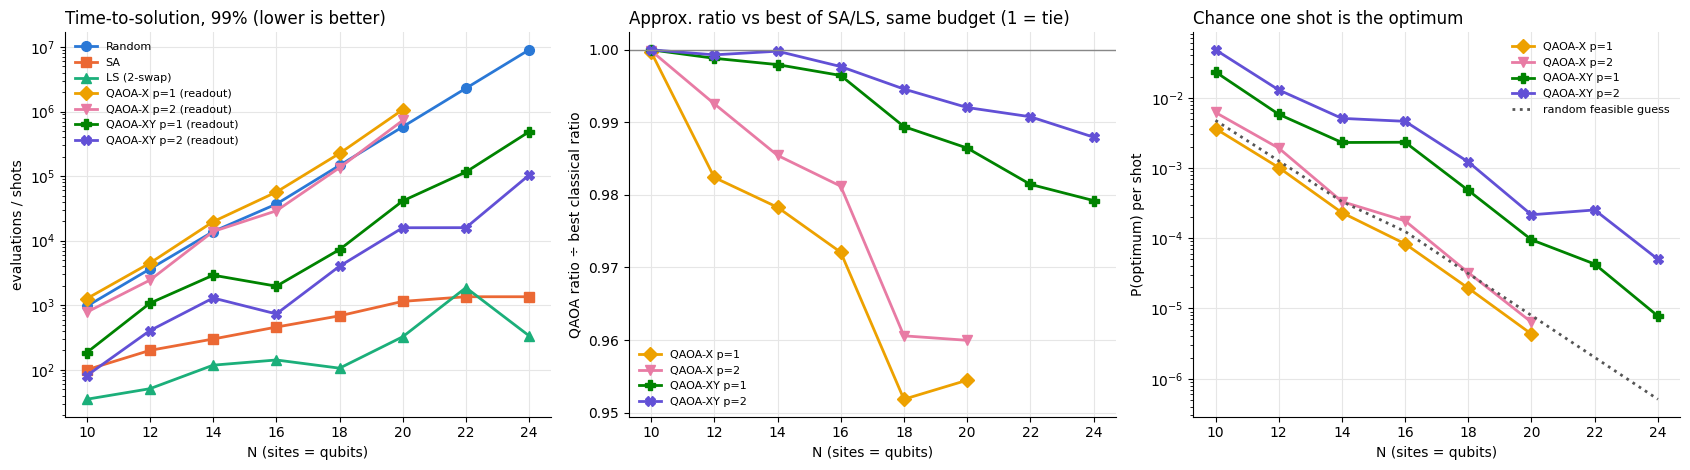

In [12]:
import matplotlib.pyplot as plt
COL = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
MK  = ["o", "s", "^", "D", "v", "P", "X", "*"]
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
                     "grid.color": "#e6e6e6", "grid.linewidth": 0.8, "lines.linewidth": 2, "font.size": 10})

fig, ax = plt.subplots(1, 3, figsize=(17, 4.8))

# (a) TTS99 vs N
series = [("Random", ci.groupby("N").random_tts_evals.median()),
          ("SA", ci.groupby("N").sa_tts_evals.median()),
          ("LS (2-swap)", ci.groupby("N").ls_tts_evals.median())]
for lab, g in qa.groupby("label"):
    series.append((f"{lab} (readout)", g.groupby("N").qaoa_tts_shots.median()))
for k, (lab, s) in enumerate(series):
    s = s.replace(np.inf, np.nan)
    ax[0].plot(s.index, s.values, marker=MK[k % 8], ms=7, color=COL[k % 8], label=lab)
ax[0].set_yscale("log"); ax[0].set_xlabel("N (sites = qubits)"); ax[0].set_ylabel("evaluations / shots")
ax[0].set_title("Time-to-solution, 99% (lower is better)", loc="left")

for k, (lab, g) in enumerate(qa.groupby("label")):
    s = g.groupby("N")["ratio_vs_best_classical_final"].mean()
    ax[1].plot(s.index, s.values, marker=MK[(k + 3) % 8], ms=7, color=COL[(k + 3) % 8], label=lab)
ax[1].axhline(1, color="#888", lw=1)
ax[1].set_xlabel("N (sites = qubits)"); ax[1].set_ylabel("QAOA ratio ÷ best classical ratio")
ax[1].set_title("Approx. ratio vs best of SA/LS, same budget (1 = tie)", loc="left")


for k, (lab, g) in enumerate(qa.groupby("label")):
    s = g.groupby("N").P_opt.mean()
    ax[2].plot(s.index, s.values, marker=MK[(k + 3) % 8], ms=7, color=COL[(k + 3) % 8], label=lab)
Ns = np.array(sorted(ci.N.unique()))
ax[2].plot(Ns, [1 / math.comb(n, round(K_FRAC * n)) for n in Ns], ":", color="#555", label="random feasible guess")
ax[2].set_yscale("log"); ax[2].set_xlabel("N (sites = qubits)"); ax[2].set_ylabel("P(optimum) per shot")
ax[2].set_title("Chance one shot is the optimum", loc="left")
for a in ax: a.legend(fontsize=8, frameon=False)
plt.tight_layout(); plt.savefig("fastshelter_scaling.png", dpi=150); plt.show()

## 10. Download the results

In [13]:
qa.to_csv("qaoa_per_instance.csv", index=False); ci.to_csv("classical_per_instance.csv", index=False)
t1.to_csv("table1_tts.csv"); t2.to_csv("table2_matched_budget.csv"); t3.to_csv("table3_qaoa_quality.csv")
try:
    from google.colab import files
    for f in ["table1_tts.csv", "table2_matched_budget.csv", "table3_qaoa_quality.csv",
              "qaoa_per_instance.csv", "classical_per_instance.csv", "fastshelter_scaling.png"]:
        files.download(f)
except ImportError:
    print("Not in Colab - files are saved in the working folder.")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

... (2 outputs left out)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>